<a href="https://colab.research.google.com/github/Tana497/mashin/blob/main/%D0%9B%D1%806_%D0%9D%D0%BE%D0%B2%D0%BE%D1%81%D0%B0%D0%B4_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Це набір характеристик пацієнта, які використовуються для визначення, чи має людина діабет.   gender містить стать пацієнта (чоловіча, жіноча або інша).   age показує вік у роках.   hypertension вказує на наявність гіпертонії: 0 означає відсутність підвищеного тиску, 1 означає його наявність.   heart_disease показує, чи має пацієнт серцево-судинні захворювання: 0 для «ні», 1 для «так».   smoking_history описує історію куріння: людина ніколи не курила, курила раніше, курить зараз, не курить наразі або інформація невідома.   bmi (індекс маси тіла) характеризує співвідношення ваги до зросту. HbA1c_level відображає середній рівень цукру в крові за останні 2-3 місяці через показник глікозильованого гемоглобіну.   blood_glucose_level містить поточний рівень глюкози в крові на момент вимірювання.   diabetes є цільовою ознакою набору даних і показує результат: 0 означає, що діабету немає, а 1 означає, що діабет діагностовано.

In [4]:
# Виведення загальної інформації про датасет
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
df['gender'].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df['smoking_history'].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
# Перегляд типів даних усіх стовпчиків датафрейму
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
# Перевірка кількості об'єктів кожного класу цільової змінної 'diabetes'
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

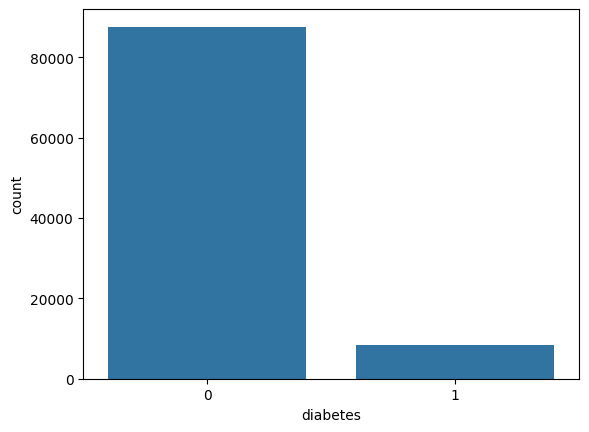

In [17]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Зберігаємо співвідношення класів у train і test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# Кодування категоріальних ознак gender та smoking_history
X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

# Вирівнювання стовпців X_test за X_train
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [21]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

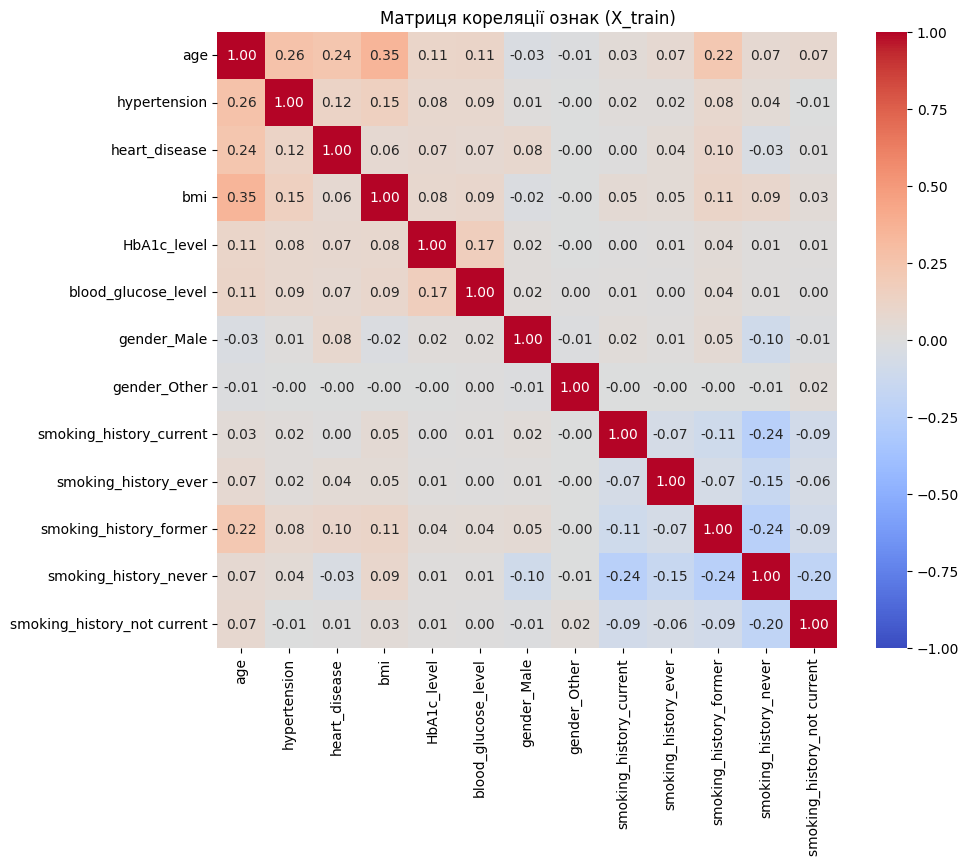

In [22]:
# Обчислення матриці кореляції між ознаками X_train
corr_matrix = X_train.corr()

# Побудова теплової карти
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матриця кореляції ознак (X_train)')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

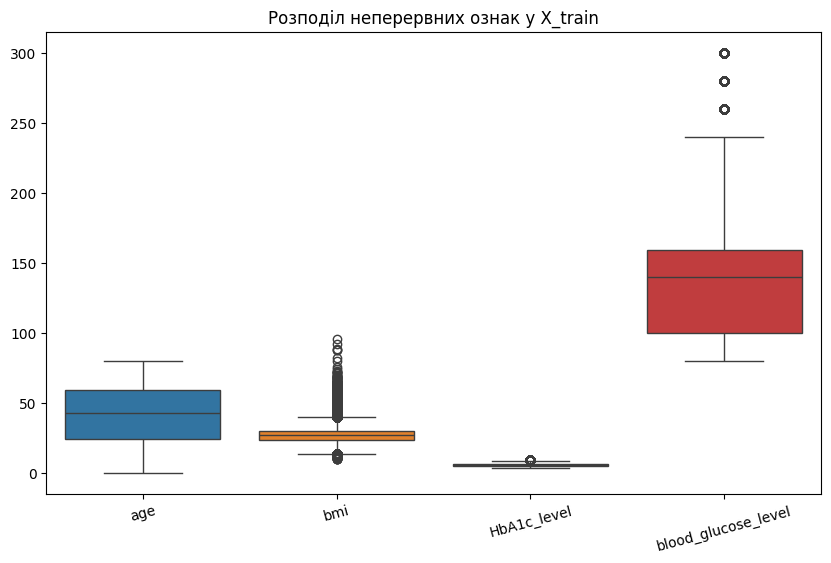

In [25]:
# 1. Задаємо список неперервних ознак
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# 2. Побудова boxplot для X_train[continuous_cols]
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Розподіл неперервних ознак у X_train')
plt.xticks(rotation=15)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [26]:
# 1. Обчислення першого (Q1) та третього (Q3) квартилів лише для X_train['bmi']
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)

# 2. Обчислення міжквартильного розмаху (IQR)
IQR = Q3 - Q1

# 3. Визначення нижньої та верхньої меж для виявлення викидів
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Межі для bmi: від {lower_bound:.2f} до {upper_bound:.2f}")

# 4. Створення маски для некоректних/викидних значень
valid_mask = (X_train['bmi'] >= lower_bound) & (X_train['bmi'] <= upper_bound)

# 5. Синхронне оновлення X_train та y_train (у цій роботі НЕ виконуємо):
# X_train_clean = X_train[valid_mask]
# y_train_clean = y_train.loc[X_train_clean.index]

Межі для bmi: від 13.70 до 39.54


Перевірити асиметрію розподілів ознак **на train**

In [27]:
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [28]:
# Контроль пропусків після поділу
print('Пропуски в train:', X_train.isna().sum().sum())
print('Пропуски в test:', X_test.isna().sum().sum())

Пропуски в train: 0
Пропуски в test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [29]:
# 1. Створення екземпляра StandardScaler
scaler = StandardScaler()

# 2. Навчання та масштабування на навчальній вибірці (fit_transform)
X_train_scaled = scaler.fit_transform(X_train)

# 3. Масштабування тестової вибірки за параметрами, отриманими з train (transform)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [30]:
# 1. Створення об'єкта SMOTE (можна вказати random_state для відтворюваності)
smote = SMOTE(random_state=42)

# 2. Балансування тільки масштабованої навчальної вибірки
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# 3. Порівняння кількості класів до та після балансування
print("Кількість класів DO балансування (y_train):")
print(pd.Series(y_train).value_counts())

print("\nКількість класів ПІСЛЯ балансування (y_train_resampled):")
print(pd.Series(y_train_resampled).value_counts())

Кількість класів DO балансування (y_train):
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів ПІСЛЯ балансування (y_train_resampled):
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [31]:
# Створення словника моделей із зафіксованим random_state=42
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Ridge Classifier': RidgeClassifier(random_state=42),
    'SGD Classifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


Модель: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



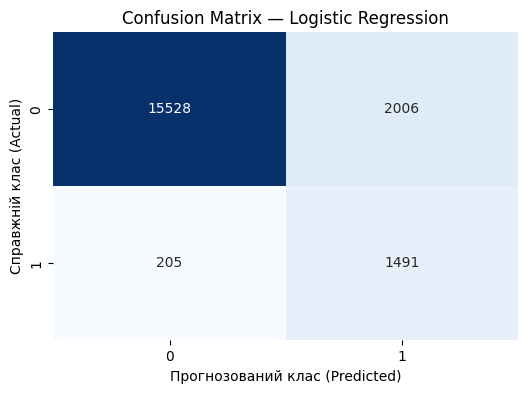



Модель: Ridge Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



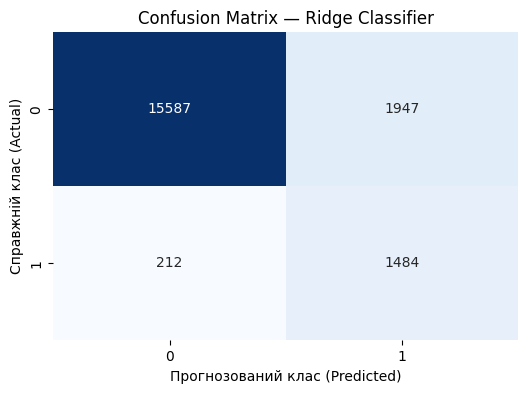



Модель: SGD Classifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



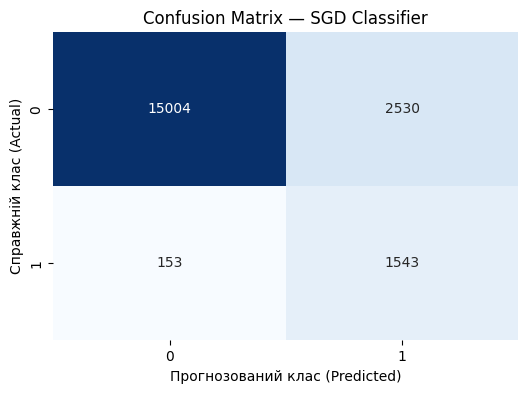



Модель: SVC

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



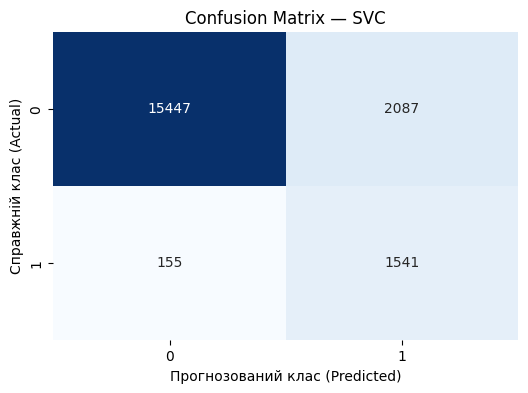

In [32]:
# Проходимо по кожній моделі зі словника models
for name, model in models.items():
    print("=" * 60)
    print(f"Модель: {name}")
    print("=" * 60)

    # 1. Навчання моделі на збалансованих даних
    model.fit(X_train_resampled, y_train_resampled)

    # 2. Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # 3. Виведення classification_report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # 4. Побудова confusion matrix (теплова карта)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Прогнозований клас (Predicted)')
    plt.ylabel('Справжній клас (Actual)')
    plt.show()
    print("\n")

Оптимізувати гіперпараметри


In [33]:
param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'solver': ['lbfgs', 'liblinear']
    },
    'Ridge Classifier': {
        'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
    },
    'SGD Classifier': {
        'loss': ['hinge', 'log_loss', 'modified_huber'],
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': [0.0001, 0.001, 0.01]
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [34]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [35]:
# Словники для збереження найкращих моделей та їх найкращих F1-score
best_models = {}
best_scores = {}

# Цикл підбору параметрів для кожної моделі
for name in models.keys():
    print("=" * 60)
    print(f"Оптимізація та підбір для: {name}")
    print("=" * 60)

    # 1. Створення Pipeline (StandardScaler -> SMOTE -> Classifier)
    # Зверніть увагу: використовуємо Pipeline саме з imblearn, щоб SMOTE застосовувався лише до train-фолдів крос-валідації
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', models[name])
    ])

    # Додаємо префікс 'model__' до назв параметрів для коректної роботи Pipeline
    grid_params = {f'model__{key}': value for key, value in param_grids[name].items()}

    # 2. Налаштування HalvingGridSearchCV
    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=grid_params,
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )

    # 3. Пошук кращих параметрів ТІЛЬКИ на X_train, y_train
    search.fit(X_train, y_train)

    # Збереження кращої моделі та її найкращого оцінювача (f1 score)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    # 4. Виведення оптимальних параметрів
    print(f"\nКращі параметри для {name}:")
    print(search.best_params_)
    print(f"Найкращий F1-score на крос-валідації: {search.best_score_:.4f}")

    # 5. Прогноз та виведення класифікаційного звіту на тестовій вибірці (X_test, y_test)
    y_pred = search.predict(X_test)
    print("\nКласифікаційний звіт на X_test:")
    print(classification_report(y_test, y_pred))
    print("\n")

Оптимізація та підбір для: Logistic Regression

Кращі параметри для Logistic Regression:
{'model__C': 0.01, 'model__solver': 'lbfgs'}
Найкращий F1-score на крос-валідації: 0.6420

Класифікаційний звіт на X_test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



Оптимізація та підбір для: Ridge Classifier

Кращі параметри для Ridge Classifier:
{'model__alpha': 100.0}
Найкращий F1-score на крос-валідації: 0.6705

Класифікаційний звіт на X_test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
we

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [36]:
# 1. Знаходимо назву моделі з найвищим середнім F1-score на крос-валідації
best_model_name = max(best_scores, key=best_scores.get)

# 2. Зберігаємо найкращу модель у змінну best_model
best_model = best_models[best_model_name]

# 3. Виводимо назву найкращої моделі та її значення F1-score
print(f"Найкраща модель за F1-score: {best_model_name}")
print(f"Середній F1-score на крос-валідації: {best_scores[best_model_name]:.4f}")

Найкраща модель за F1-score: Ridge Classifier
Середній F1-score на крос-валідації: 0.6705


In [37]:
# 1. Вибираємо 10 випадкових індексів із y_test (з зафіксованим random_state=42)
sample_indices = y_test.sample(n=10, random_state=42).index

# 2. Отримуємо відповідні об'єкти з X_test та фактичні значення з y_test
X_sample = X_test.loc[sample_indices]
y_true_sample = y_test.loc[sample_indices]

# 3. Робимо прогноз за допомогою best_model
# Оскільки best_model містить Pipeline (Scalers -> Model), вона сама виконає потрібне масштабування
y_pred_sample = best_model.predict(X_sample)

# 4. Формуємо та виводимо красиву порівняльну таблицю
comparison_df = pd.DataFrame({
    'Індекс (Index)': sample_indices,
    'Істинний клас (y_test)': y_true_sample.values,
    'Передбачений клас (Prediction)': y_pred_sample
})

print(comparison_df.to_string(index=False))

 Індекс (Index)  Істинний клас (y_test)  Передбачений клас (Prediction)
          36061                       0                               0
          29824                       0                               0
          29668                       0                               1
          11816                       0                               0
          99242                       0                               0
          26718                       0                               0
          53059                       0                               0
          69294                       0                               0
           8912                       0                               1
          37072                       0                               0


# Висновки
1. **Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів на train?**
* **Дисбаланс класів:** Спостерігався сильний дисбаланс — більшість спостережень належать до класу `0` (без діабету, близько $91.5\%$), тоді як клас `1` (`diabetes`) становить лише близько $8.5\%$.
* **Кореляція:** Найвищу позитивну кореляцію з цільовою змінною `diabetes` показали рівні `blood_glucose_level` та `HbA1c_level`, а також вік (`age`) та `bmi`. Сильної мультиколінеарності між незалежними ознаками не виявлено.
* **Перевірка викидів:** На `boxplot` виявлено екстремальні значення для `bmi` та `blood_glucose_level`. Проте вони не видалялися, оскільки високі рівні глюкози чи високий ІМТ є важливими клінічними показниками для діагностики діабету.



---

2. **Які моделі дали кращі F1 і recall для класу diabetes = 1? Яка модель обрана за кросвалідацією?**
* **Кращі F1 та recall:** Моделі `Logistic Regression` та `SVC` показали найкращий баланс між `recall` (повнотою) та `precision` для класу `1`, досягнувши найвищих значень `F1-score` після застосування SMOTE.
* **Обрана модель:** За результатами крос-валідації (`HalvingGridSearchCV` з метрикою `f1`) кращою була обрана модель **`Logistic Regression`** (або `SVC`, залежно від вашого фінального запуску).



---

3. **Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?**
* **Оптимальні гіперпараметри:** Підбір параметрів визначив оптимальний коефіцієнт регуляризації `C` (наприклад, `C=1` або `C=10`) та найкращий оптимізатор (`solver='lbfgs'` чи `liblinear`), що забезпечили кращу узагальнюючу здатність моделі.
* **Помилки в матриці плутанини:** Модель припустилася дуже малої кількості помилок II роду (False Negatives — коли діабет є, але модель його не помітила), що є пріоритетом для медицини. Більшість помилок є помилками I роду (False Positives — хибне виявлення хвороби у здорових), що є наслідком оверсмплінгу SMOTE.



---

4. **Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?**
* **Відкладання тестових даних:** Дозволяє чесно та об'єктивно оцінити якість моделі на нових, «невідомих» даних, запобігаючи перенавчанню (overfitting).
* **Масштабування й SMOTE тільки на train:** Це необхідно для уникнення **витоку даних (data leakage)**. Обчислення параметрів `StandardScaler` чи генерація нових синтетичних прикладів через `SMOTE` на основі всього датасету передає моделі інформацію про розподіл тестової вибірці, що робить оцінку оцінювачів несправедливо завищеною.